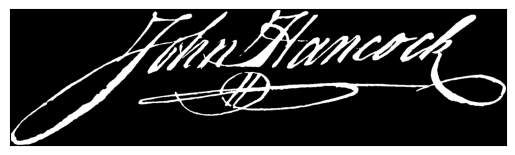

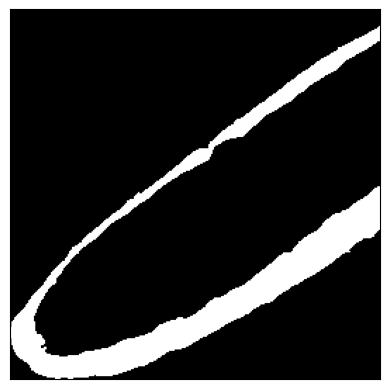

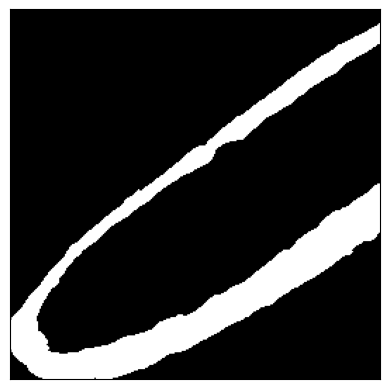

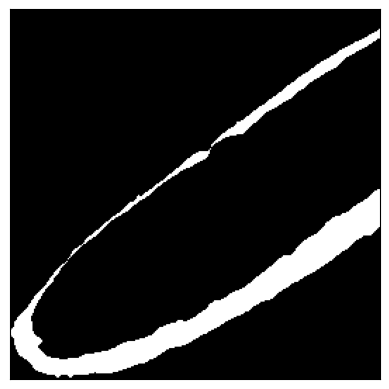

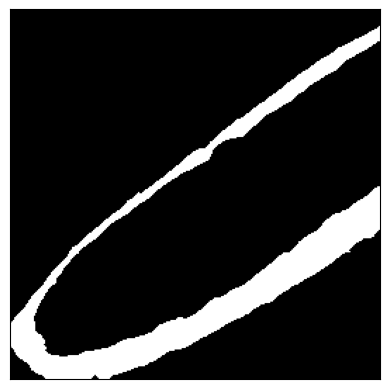

In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

img=cv.imread('./ch3/JohnHancocksSignature.png',cv.IMREAD_UNCHANGED) 

t,bin_img=cv.threshold(img[:,:,3],0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)
plt.imshow(bin_img,cmap='gray'), plt.xticks([]), plt.yticks([])
plt.show() 

b=bin_img[bin_img.shape[0]//2:bin_img.shape[0],0:bin_img.shape[0]//2+1]
plt.imshow(b,cmap='gray'), plt.xticks([]), plt.yticks([])
plt.show()

se=np.uint8([[0,0,1,0,0],			# 구조 요소
            [0,1,1,1,0],
            [1,1,1,1,1],
            [0,1,1,1,0],
            [0,0,1,0,0]])

b_dilation=cv.dilate(b,se,iterations=1)	# 팽창
plt.imshow(b_dilation,cmap='gray'), plt.xticks([]), plt.yticks([])
plt.show()

b_erosion=cv.erode(b,se,iterations=1)	# 침식
plt.imshow(b_erosion,cmap='gray'), plt.xticks([]), plt.yticks([])
plt.show()

b_closing=cv.erode(cv.dilate(b,se,iterations=1),se,iterations=1)	# 닫기
plt.imshow(b_closing,cmap='gray'), plt.xticks([]), plt.yticks([])
plt.show()

In [5]:
import cv2 as cv
import numpy as np

img=cv.imread('./ch3/soccer.jpg') 
img=cv.resize(img,dsize=(0,0),fx=0.25,fy=0.25)

def gamma(f,gamma=1.0):
    f1=f/255.0			# L=256이라고 가정
    return np.uint8(255*(f1**gamma))

gc=np.hstack((gamma(img,0.5),gamma(img,0.75),gamma(img,1.0),gamma(img,2.0),gamma(img,3.0)))
cv.imshow('gamma',gc)

cv.waitKey()
cv.destroyAllWindows()

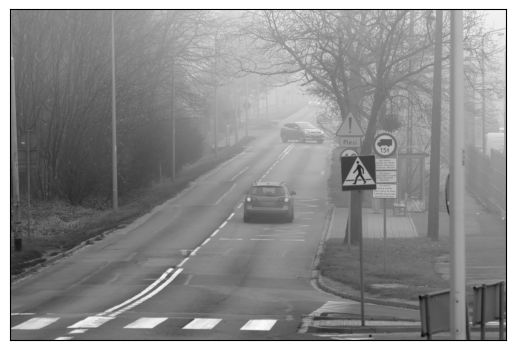

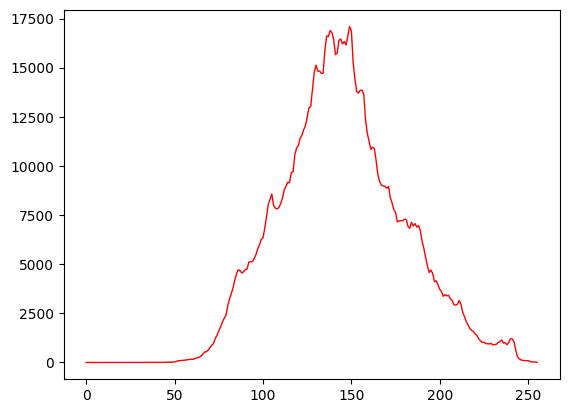

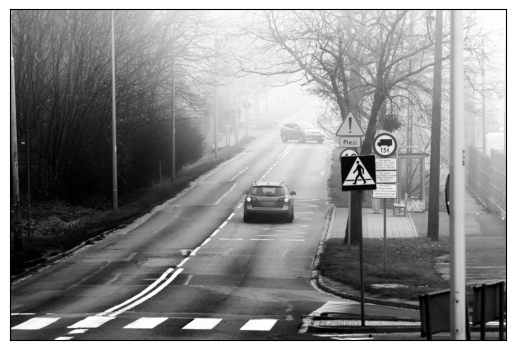

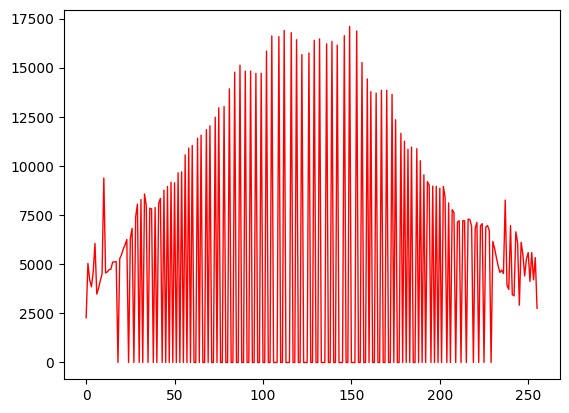

([<matplotlib.lines.Line2D at 0x191322c22d0>], None)

In [7]:
import cv2 as cv
import matplotlib.pyplot as plt

img=cv.imread('./ch3/mistyroad.jpg') 

gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)		# 명암 영상으로 변환하고 출력
plt.imshow(gray,cmap='gray'), plt.xticks([]), plt.yticks([]), plt.show()

h=cv.calcHist([gray],[0],None,[256],[0,256])	# 히스토그램을 구해 출력
plt.plot(h,color='r',linewidth=1), plt.show()

#평활화 하는 함수
equal=cv.equalizeHist(gray)			# 히스토그램을 평활화하고 출력
plt.imshow(equal,cmap='gray'), plt.xticks([]), plt.yticks([]), plt.show()

h=cv.calcHist([equal],[0],None,[256],[0,256])	# 히스토그램을 구해 출력
plt.plot(h,color='r',linewidth=1), plt.show()

In [9]:
import cv2 as cv
import numpy as np

img=cv.imread('./ch3/soccer.jpg')
img=cv.resize(img,dsize=(0,0),fx=0.4,fy=0.4)
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
#soccer이라는 텍스트를 붙임
cv.putText(gray,'soccer',(10,20),cv.FONT_HERSHEY_SIMPLEX,0.7,(255,255,255),2)
cv.imshow('Original',gray)

smooth=np.hstack((cv.GaussianBlur(gray,(5,5),0.0),cv.GaussianBlur(gray,(9,9),0.0),cv.GaussianBlur(gray,(15,15),0.0)))
cv.imshow('Smooth',smooth)

femboss=np.array([[-1.0, 0.0, 0.0],
                  [ 0.0, 0.0, 0.0],
                  [ 0.0, 0.0, 1.0]])

gray16=np.int16(gray)
emboss=np.uint8(np.clip(cv.filter2D(gray16,-1,femboss)+128,0,255))
emboss_bad=np.uint8(cv.filter2D(gray16,-1,femboss)+128)
emboss_worse=cv.filter2D(gray,-1,femboss)

cv.imshow('Emboss',emboss)
cv.imshow('Emboss_bad',emboss_bad)
cv.imshow('Emboss_worse',emboss_worse)

cv.waitKey()
cv.destroyAllWindows()

In [10]:
import cv2 as cv

img=cv.imread('./ch3/rose.png')
patch=img[250:350,170:270,:]

img=cv.rectangle(img,(170,250),(270,350),(255,0,0),3)
patch1=cv.resize(patch,dsize=(0,0),fx=5,fy=5,interpolation=cv.INTER_NEAREST)
patch2=cv.resize(patch,dsize=(0,0),fx=5,fy=5,interpolation=cv.INTER_LINEAR)
patch3=cv.resize(patch,dsize=(0,0),fx=5,fy=5,interpolation=cv.INTER_CUBIC)

cv.imshow('Original',img)
cv.imshow('Resize nearest',patch1) 
cv.imshow('Resize bilinear',patch2) 
cv.imshow('Resize bicubic',patch3) 

cv.waitKey()
cv.destroyAllWindows()

In [5]:
import cv2 as cv

img=cv.imread('lacko1.png')
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)

grad_x=cv.Sobel(gray,cv.CV_32F,1,0,ksize=3)	# 소벨 연산자 적용
grad_y=cv.Sobel(gray,cv.CV_32F,0,1,ksize=3)

sobel_x=cv.convertScaleAbs(grad_x)	# 절대값을 취해 양수 영상으로 변환
sobel_y=cv.convertScaleAbs(grad_y)

edge_strength=cv.addWeighted(sobel_x,0.5,sobel_y,0.5,0)	# 에지 강도 계산

cv.imshow('Original',gray)
cv.imshow('sobelx',sobel_x)
cv.imshow('sobely',sobel_y)
cv.imshow('edge strength',edge_strength)

cv.waitKey()
cv.destroyAllWindows()

In [8]:
import cv2 as cv

img=cv.imread('lacko1.png')	# 영상 읽기

gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)

canny1=cv.Canny(gray,50,150)	# Tlow=50, Thigh=150으로 설정
canny2=cv.Canny(gray,100,200)	# Tlow=100, Thigh=200으로 설정

cv.imshow('Original',gray)
cv.imshow('Canny1',canny1)
cv.imshow('Canny2',canny2)

cv.waitKey()
cv.destroyAllWindows()

In [9]:
import cv2 as cv

img=cv.imread('lacko1.png')	# 영상 읽기

gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)

canny1=cv.Canny(gray,50,150)	# Tlow=50, Thigh=150으로 설정
canny2=cv.Canny(gray,100,200)	# Tlow=100, Thigh=200으로 설정


grad_x=cv.Sobel(gray,cv.CV_32F,1,0,ksize=3)	# 소벨 연산자 적용
grad_y=cv.Sobel(gray,cv.CV_32F,0,1,ksize=3)

sobel_x=cv.convertScaleAbs(grad_x)	# 절대값을 취해 양수 영상으로 변환
sobel_y=cv.convertScaleAbs(grad_y)

edge_strength=cv.addWeighted(sobel_x,0.5,sobel_y,0.5,0)	# 에지 강도 계산
cv.imshow('Original',gray)
cv.imshow('Canny1',canny1)
cv.imshow('Canny2',canny2)
cv.imshow('Original',gray)
cv.imshow('sobelx',sobel_x)
cv.imshow('sobely',sobel_y)
cv.imshow('edge strength',edge_strength)
cv.waitKey()
cv.destroyAllWindows()

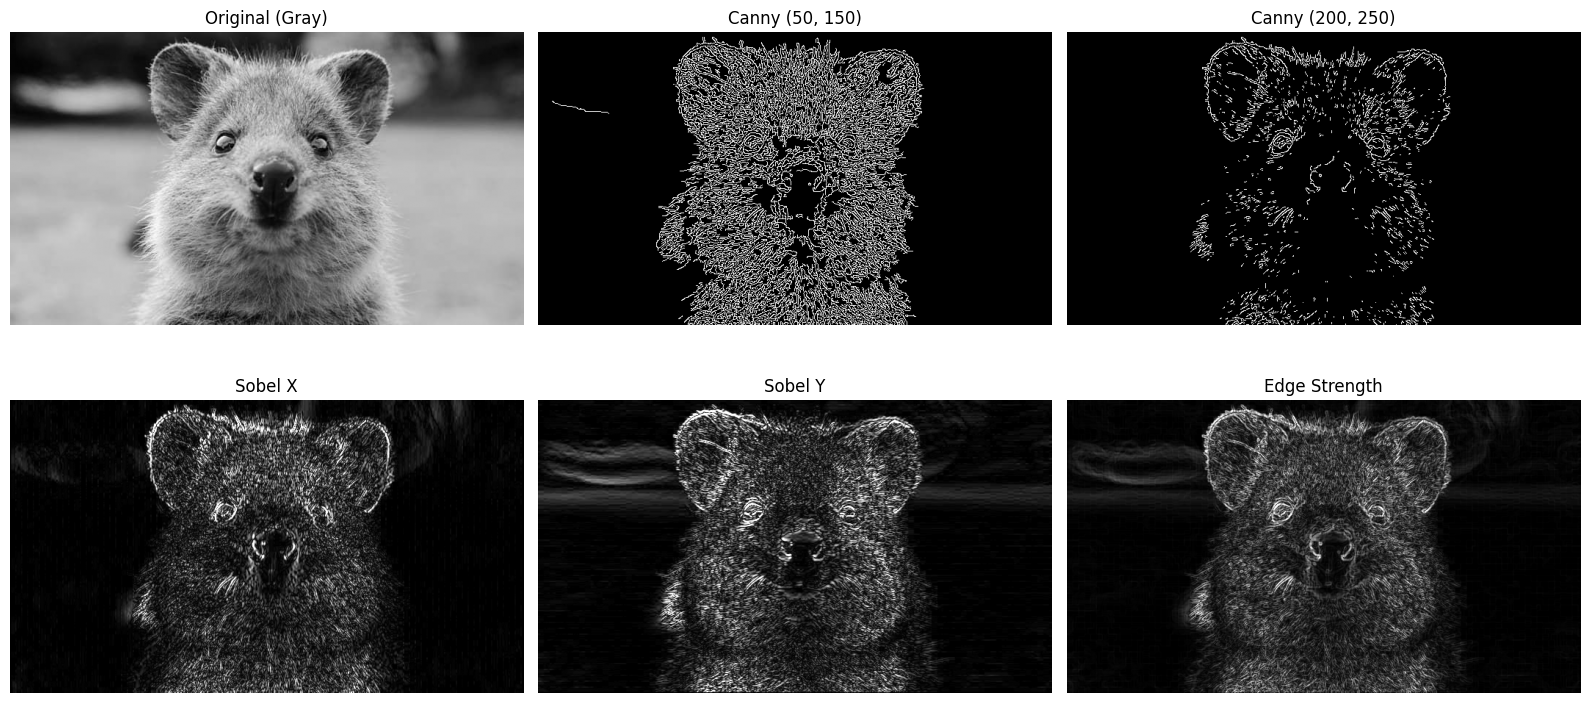

In [19]:
import cv2 as cv
import matplotlib.pyplot as plt

# 1. 영상 읽기
img = cv.imread('quaqa.jpg')

if img is None:
    print("이미지를 불러올 수 없습니다. 파일 이름을 확인해주세요.")
else:
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # 2. 캐니 에지 검출 (임계값 다르게 적용)
    canny1 = cv.Canny(gray, 50, 150)   # Tlow=50, Thigh=150
    canny2 = cv.Canny(gray, 200, 250)  # Tlow=100, Thigh=200

    # 3. 소벨 연산자 적용
    grad_x = cv.Sobel(gray, cv.CV_32F, 1, 0, ksize=3)
    grad_y = cv.Sobel(gray, cv.CV_32F, 0, 1, ksize=3)

    sobel_x = cv.convertScaleAbs(grad_x)  # 절댓값을 취해 양수 영상으로 변환
    sobel_y = cv.convertScaleAbs(grad_y)

    edge_strength = cv.addWeighted(sobel_x, 0.5, sobel_y, 0.5, 0)

    plt.figure(figsize=(16, 8))

    plt.subplot(2, 3, 1)
    plt.imshow(gray, cmap='gray')
    plt.title('Original (Gray)')
    plt.axis('off')

    plt.subplot(2, 3, 2)
    plt.imshow(canny1, cmap='gray')
    plt.title('Canny (50, 150)')
    plt.axis('off')

    plt.subplot(2, 3, 3)
    plt.imshow(canny2, cmap='gray')
    plt.title('Canny (200, 250)')
    plt.axis('off')

    plt.subplot(2, 3, 4)
    plt.imshow(sobel_x, cmap='gray')
    plt.title('Sobel X')
    plt.axis('off')

    plt.subplot(2, 3, 5)
    plt.imshow(sobel_y, cmap='gray')
    plt.title('Sobel Y')
    plt.axis('off')

    plt.subplot(2, 3, 6)
    plt.imshow(edge_strength, cmap='gray')
    plt.title('Edge Strength')
    plt.axis('off')

    plt.tight_layout()
    plt.show()  # 별도 창 없이 아래 출력창에 바로 띄워집니다.
    #1 오리지널 그림
    #2. canny 임계값을 작게했을때 대부분의 선들이 출력되는것을 확인할 수있다
    #3. canny 임계값을 크게 해서 기존보다 색이 얕아지고 선도 얇아졌다
    #4. 가로방향 미분을 수행해서 세로방향의 선들이 더 밝게 보인다. 배부분이 확실히 밝다
    #5. 세로방향 미분을 수행해서 가로방향 선들이 더 밝게 보인다. 솔직히 잘 모르겠다
    #6. 가로와 세로 미분한 값을 합성해서 에지 강도를 표현했다.
    # 선이 깔끔하게 그려진것은 canny인 것 같다. 하지만 윤곽석인 강조되어 시각적으로 확실히 들어오는건 소벨이다.

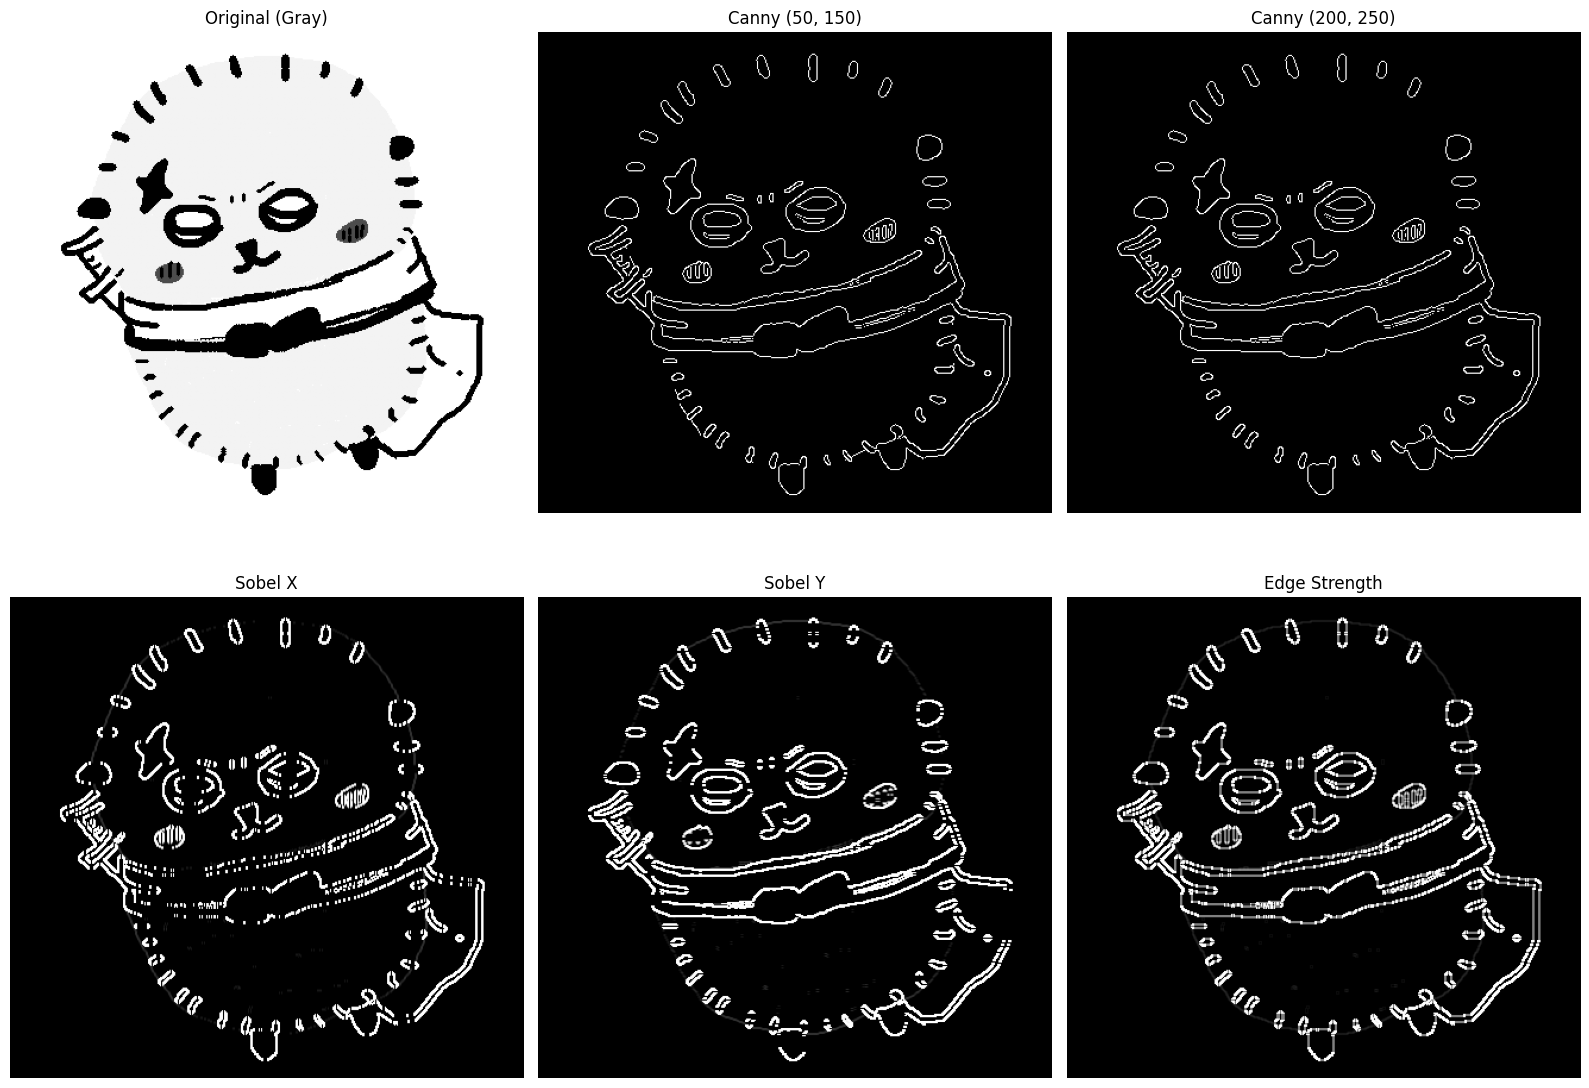

In [21]:
import cv2 as cv
import matplotlib.pyplot as plt

# 1. 영상 읽기
img = cv.imread('lacko.png')

if img is None:
    print("이미지를 불러올 수 없습니다. 파일 이름을 확인해주세요.")
else:
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # 2. 캐니 에지 검출 (임계값 다르게 적용)
    canny1 = cv.Canny(gray, 50, 150)   # Tlow=50, Thigh=150
    canny2 = cv.Canny(gray, 200, 250)  # Tlow=100, Thigh=200

    # 3. 소벨 연산자 적용
    grad_x = cv.Sobel(gray, cv.CV_32F, 1, 0, ksize=3)
    grad_y = cv.Sobel(gray, cv.CV_32F, 0, 1, ksize=3)

    sobel_x = cv.convertScaleAbs(grad_x)  # 절댓값을 취해 양수 영상으로 변환
    sobel_y = cv.convertScaleAbs(grad_y)

    edge_strength = cv.addWeighted(sobel_x, 0.5, sobel_y, 0.5, 0)

    plt.figure(figsize=(16, 12))

    plt.subplot(2, 3, 1)
    plt.imshow(gray, cmap='gray')
    plt.title('Original (Gray)')
    plt.axis('off')

    plt.subplot(2, 3, 2)
    plt.imshow(canny1, cmap='gray')
    plt.title('Canny (50, 150)')
    plt.axis('off')

    plt.subplot(2, 3, 3)
    plt.imshow(canny2, cmap='gray')
    plt.title('Canny (200, 250)')
    plt.axis('off')

    plt.subplot(2, 3, 4)
    plt.imshow(sobel_x, cmap='gray')
    plt.title('Sobel X')
    plt.axis('off')

    plt.subplot(2, 3, 5)
    plt.imshow(sobel_y, cmap='gray')
    plt.title('Sobel Y')
    plt.axis('off')

    plt.subplot(2, 3, 6)
    plt.imshow(edge_strength, cmap='gray')
    plt.title('Edge Strength')
    plt.axis('off')

    plt.tight_layout()
    plt.show()  # 별도 창 없이 아래 출력창에 바로 띄워집니다.
    #1 오리지널 그림
    #2. canny 임계값을 작게했을때 대부분의 선들이 출력되는것을 확인할 수있다
    #3. canny 임계값을 크게 해서 기존보다 색이 얕아지고 선도 얇아졌다
    #4. 가로방향 미분을 수행해서 세로방향의 선들이 더 밝게 보인다. 배부분이 확실히 밝다
    #5. 세로방향 미분을 수행해서 가로방향 선들이 더 밝게 보인다. 솔직히 잘 모르겠다
    #6. 가로와 세로 미분한 값을 합성해서 에지 강도를 표현했다.
    # 선이 깔끔하게 그려진것은 canny인 것 같다. 하지만 윤곽석인 강조되어 시각적으로 확실히 들어오는건 소벨이다.